# Citi Bike: How New York Moves by Bike

Three months of Citi Bike trips: when people ride, how rain changes that, which stations empty out in the morning, what kinds of stations exist, and a next-day forecast of each station's rides.

DuckDB SQL (`queries.sql`) does the cleaning and heavy aggregation. pandas, NumPy, and scikit-learn take over once the data is small.

## Part 1: Setup

In [1]:
from pathlib import Path

import duckdb
import holidays
import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, silhouette_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

plt.rcParams.update({"font.size": 12, "figure.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, RED = "#0073ff", "#ff7640", "#e24b4a"
HOUR_LABELS = ["12 am", "3 am", "6 am", "9 am", "12 pm", "3 pm", "6 pm", "9 pm"]  # ticks every 3 hours


def query(name):
    """Return the SQL text of one named query from queries.sql."""
    sql = Path("queries.sql").read_text()
    return sql.split(f"-- name: {name}\n")[1].split("-- name:")[0]


def save_chart(fig, filename, source):
    """Add a source note at the bottom and save to docs/ at 1200 x 700 px."""
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.015, source, fontsize=9, color="gray")
    fig.savefig(Path("docs") / filename, dpi=100)

Clean the raw CSVs with DuckDB (only the first time; the result is saved as `data/trips.parquet`), then check that cleaning removed rows rather than adding any.

In [2]:
Path("docs").mkdir(exist_ok=True)
con = duckdb.connect()

if not Path("data/trips.parquet").exists():
    con.execute(query("clean_trips"))

raw_rows = con.sql("SELECT COUNT(*) FROM read_csv('data/raw/**/*.csv', all_varchar = true, union_by_name = true)").fetchone()[0]
clean_rows = con.sql("SELECT COUNT(*) FROM 'data/trips.parquet'").fetchone()[0]
assert clean_rows < raw_rows
print(f"Raw rows: {raw_rows:,}   Clean trips: {clean_rows:,}   Removed: {raw_rows - clean_rows:,}")

Raw rows: 15,623,841   Clean trips: 15,613,996   Removed: 9,845


Daily totals give the date range. That range sets which holidays to load (registered in DuckDB so the SQL can skip them) and which days of weather to fetch. The weather is saved to `data/` on the first run and read from disk after that: the weather service revises recent data, so downloading it again could change the model results slightly between runs.

In [3]:
daily = con.sql(query("daily_trips")).df()
start, end = daily["date"].min(), daily["date"].max()
TRIPS_SOURCE = f"Source: Citi Bike trip data, {start:%b %-d} to {end:%b %-d, %Y}"
print(f"{len(daily)} days, {start:%Y-%m-%d} to {end:%Y-%m-%d}")

ny_holidays = holidays.country_holidays("US", subdiv="NY", years=range(start.year, end.year + 1))
holidays_df = pd.DataFrame({"date": pd.to_datetime(list(ny_holidays.keys())), "name": list(ny_holidays.values())})
holidays_df = holidays_df[holidays_df["date"].between(start, end)].sort_values("date").reset_index(drop=True)
con.register("holidays", holidays_df)
holidays_df

92 days, 2026-06-01 to 2026-08-31


,date,name
0,2026-06-19,Juneteenth National Independence Day
1,2026-07-03,Independence Day (observed)
2,2026-07-04,Independence Day


In [4]:
WEATHER_FILE = Path(f"data/weather_{start:%Y-%m-%d}_{end:%Y-%m-%d}.csv")  # saved once, so re-runs use identical weather

if not WEATHER_FILE.exists():
    params = {
        "latitude": 40.7812, "longitude": -73.9665,  # Central Park
        "daily": "temperature_2m_max,precipitation_sum",
        "temperature_unit": "fahrenheit", "precipitation_unit": "inch",
        "timezone": "America/New_York",
        "start_date": f"{start:%Y-%m-%d}", "end_date": f"{end:%Y-%m-%d}",
    }
    response = httpx.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
    response.raise_for_status()
    weather = pd.DataFrame(response.json()["daily"])
    weather = weather.rename(columns={"time": "date", "temperature_2m_max": "temp_max_f", "precipitation_sum": "precip_in"})
    weather.to_csv(WEATHER_FILE, index=False)

weather = pd.read_csv(WEATHER_FILE, parse_dates=["date"])
assert len(weather) == len(daily) and weather.notna().all().all()
weather.head()

,date,temp_max_f,precip_in
0,2026-06-01,71.2,0.0
1,2026-06-02,77.4,0.0
2,2026-06-03,84.7,0.0
3,2026-06-04,89.1,0.0
4,2026-06-05,92.6,0.0


## Part 2: Findings

### 1. Commute rhythm

SQL counts trips for every date and hour. pandas marks weekends (holidays count as weekend days, since most people are off work) and averages each hour across days.

In [5]:
hourly = con.sql(query("hourly_trips")).df()
assert len(hourly) == len(daily) * 24  # every hour of every day has trips, so a mean over rows is a mean over days
hourly["is_weekend"] = (hourly["date"].dt.dayofweek >= 5) | hourly["date"].isin(holidays_df["date"])

rhythm = hourly.pivot_table(index="hour", columns="is_weekend", values="trips", aggfunc="mean")
rhythm.columns = ["Weekday", "Weekend or holiday"]
print("Weekday peaks:", rhythm["Weekday"].loc[:11].idxmax(), "h and", rhythm["Weekday"].loc[12:].idxmax(), "h")
print("Weekend peak: ", rhythm["Weekend or holiday"].idxmax(), "h")
rhythm.loc[[8, 14, 17]].round(0)

Weekday peaks: 8 h and 17 h
Weekend peak:  14 h


,Weekday,Weekend or holiday
hour,,
8,12563.0,4231.0
14,8771.0,12362.0
17,16410.0,11846.0


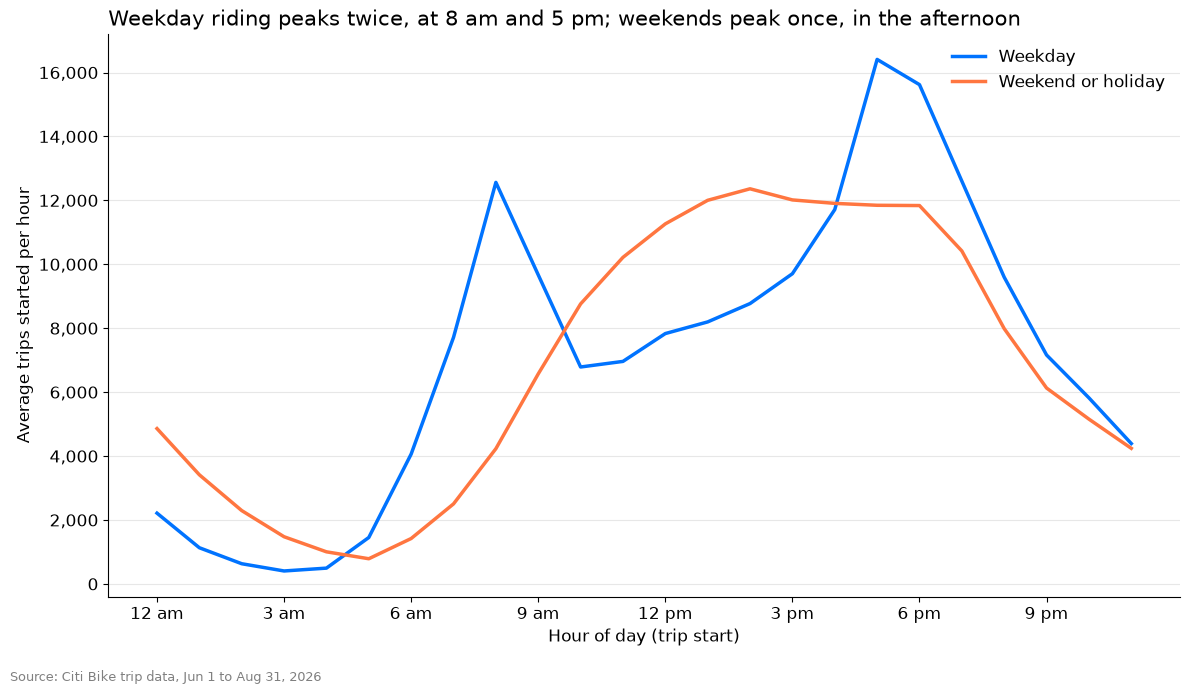

In [6]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(rhythm.index, rhythm["Weekday"], color=BLUE, linewidth=2.5, label="Weekday")
ax.plot(rhythm.index, rhythm["Weekend or holiday"], color=ORANGE, linewidth=2.5, label="Weekend or holiday")
ax.set_xticks(range(0, 24, 3), HOUR_LABELS)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="y", alpha=0.3)
ax.set(xlabel="Hour of day (trip start)", ylabel="Average trips started per hour")
ax.set_title("Weekday riding peaks twice, at 8 am and 5 pm; weekends peak once, in the afternoon", loc="left", fontsize=15)
ax.legend(frameon=False)
save_chart(fig, "commute_rhythm.png", TRIPS_SOURCE)

On weekdays, riding peaks at 8 am (about 12,600 trips an hour) and again, higher, at 5 pm (about 16,400): the commute. On weekends and holidays there is a single broad peak in the early afternoon (about 12,400 trips at 2 pm).

### 2. Rain

pandas merges daily trips with the weather, buckets each day's rainfall with `pd.cut`, and averages trips per bucket. The weekday-only version is shown too, since weekends have fewer trips and could land unevenly in the buckets.

In [7]:
days = daily.merge(weather, on="date", how="left")
days["rain"] = pd.cut(days["precip_in"], bins=[0, 0.01, 0.25, np.inf], right=False, labels=["Dry", "Light", "Heavy"])
days["is_weekday"] = (days["date"].dt.dayofweek < 5) & ~days["date"].isin(holidays_df["date"])


def rain_table(df):
    """Average trips and number of days per rain bucket, and the % change vs. dry days."""
    table = df.groupby("rain", observed=False)["trips"].agg(["mean", "count"])
    table["pct_vs_dry"] = (table["mean"] / table["mean"].iloc[0] - 1) * 100
    return table


rain_all = rain_table(days)
rain_weekday = rain_table(days[days["is_weekday"]])
pd.concat({"All days": rain_all, "Weekdays only": rain_weekday}, axis=1).round(1)

All days                  Weekdays only                 
           mean count pct_vs_dry          mean count pct_vs_dry
rain                                                           
Dry    186841.5    33        0.0      189118.8    23        0.0
Light  169844.1    38       -9.1      172378.7    27       -8.9
Heavy  142578.6    21      -23.7      142734.5    14      -24.5

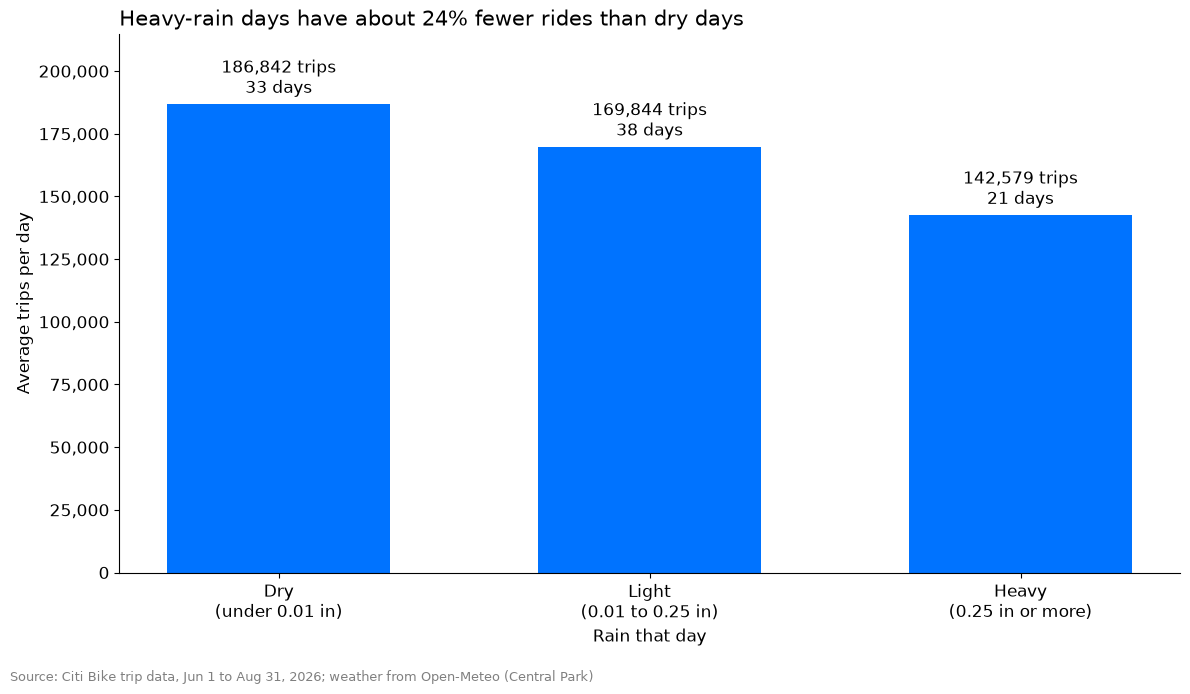

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(["Dry\n(under 0.01 in)", "Light\n(0.01 to 0.25 in)", "Heavy\n(0.25 in or more)"],
              rain_all["mean"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{m:,.0f} trips\n{n} days" for m, n in zip(rain_all["mean"], rain_all["count"])], padding=4)
ax.set_ylim(0, rain_all["mean"].max() * 1.15)  # headroom for the bar labels
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set(xlabel="Rain that day", ylabel="Average trips per day")
ax.set_title("Heavy-rain days have about 24% fewer rides than dry days", loc="left", fontsize=15)
save_chart(fig, "rain_effect.png", TRIPS_SOURCE + "; weather from Open-Meteo (Central Park)")

Heavy-rain days averaged about 142,600 trips against 186,800 on dry days (24% fewer), and light-rain days were about 9% lower. Weekdays alone show nearly the same gap (24.5% fewer on heavy-rain days), so the drop is not caused by weekends landing in the rainy buckets. Rain is a daily total, so a storm at 3 am counts the same as one at rush hour.

### 3. Morning drainers

Which stations lose the most bikes between 7 and 10 am on a normal weekday? SQL counts departures minus arrivals and divides by the number of non-holiday weekdays (not by the number of rows).

In [9]:
drainers = con.sql(query("morning_drainers")).df()
drainers.head()

,station_id,name,bikes_lost_per_weekday
0,6756.01,W 43 St & 10 Ave,64.7500
1,5659.05,E 10 St & Ave A,58.3125
2,7183.03,Riverside Blvd & W 67 St,58.2500
3,5584.04,E 6 St & Ave B,54.8750
4,6756.05,W 44 St & 11 Ave,52.7500


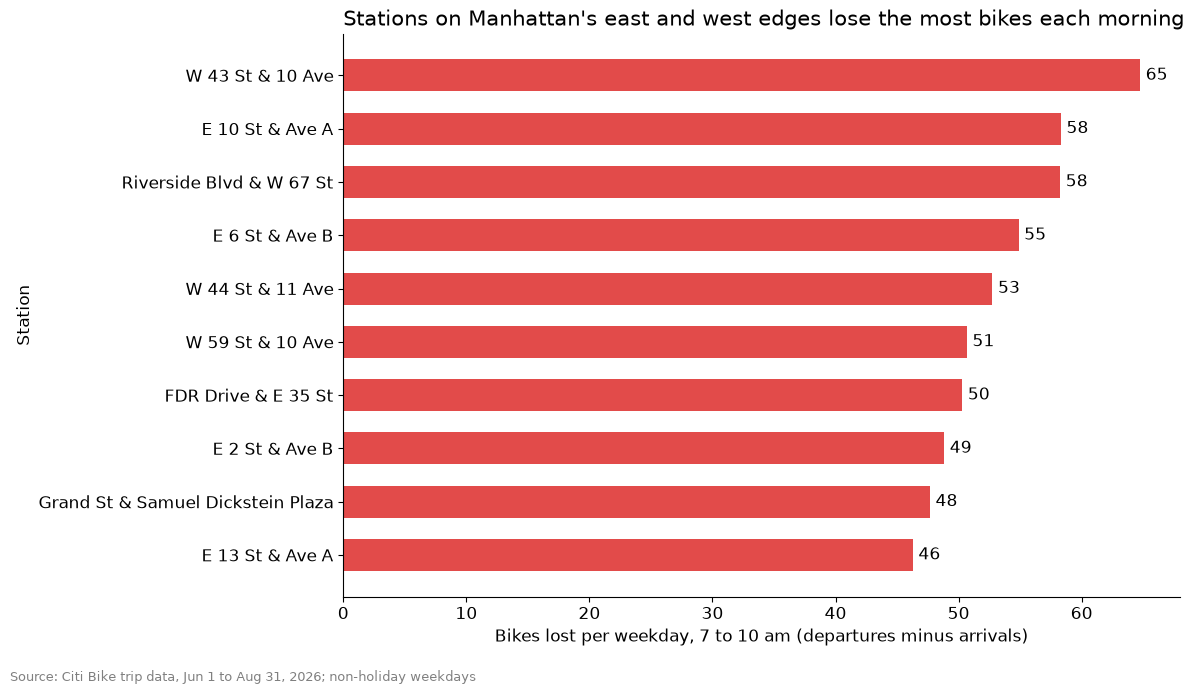

In [10]:
fig, ax = plt.subplots(figsize=(12, 7))
top = drainers.iloc[::-1]  # biggest bar at the top
bars = ax.barh(top["name"], top["bikes_lost_per_weekday"], color=RED, height=0.6)
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set(xlabel="Bikes lost per weekday, 7 to 10 am (departures minus arrivals)", ylabel="Station")
ax.set_title("Stations on Manhattan's east and west edges lose the most bikes each morning", loc="left", fontsize=15)
save_chart(fig, "morning_drainers.png", TRIPS_SOURCE + "; non-holiday weekdays")

W 43 St & 10 Ave loses about 65 bikes on an average weekday morning. All ten stations are in Manhattan near its east or west edge (Avenues A and B, 10th and 11th Avenues, Riverside Blvd, FDR Drive), where the subway is a longer walk, a likely reason people start the day on a bike there.

### 4. Station types

Every station has a daily rhythm: when it gains bikes and when it loses them. SQL gives each station's average net flow (arrivals minus departures) per hour on non-holiday weekdays. pandas pivots that to one row per station and one column per hour, keeping stations that average at least 1 trip a day.

In [11]:
stations = con.sql(query("stations")).df()
profile = con.sql(query("station_hour_profile")).df()

wide = profile.pivot(index="station_id", columns="hour", values="net_flow").fillna(0)
assert wide.shape[1] == 24
busy = stations[stations["trips_per_day"] >= 1].set_index("station_id")
wide = wide[wide.index.isin(busy.index)]
print(f"{len(wide):,} stations with at least 1 trip a day")
wide.iloc[:3, 6:10].round(2)

2,350 stations with at least 1 trip a day


hour,6,7,8,9
station_id,,,,
1234.56,0.38,0.58,0.05,0.28
1964.01,-0.08,-0.20,-0.05,-0.09
2009.04,-0.08,-0.08,-0.09,0.00


A busy station moves far more bikes than a quiet one, and KMeans would group stations by size instead of rhythm. So NumPy divides each station's row by its own average daily trips. Each value becomes "net bikes gained this hour, as a share of the station's daily trips".

In [12]:
trips_per_day = busy.loc[wide.index, "trips_per_day"].to_numpy()
X = wide.to_numpy() / trips_per_day[:, np.newaxis]  # each row divided by that station's size
X.shape

(2350, 24)

Try k = 2 to 6 and score each with the silhouette score: how much closer each station is to its own cluster than to the nearest other cluster (from -1 to 1; higher is better).

In [13]:
scores = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels)
pd.Series(scores, name="silhouette").round(3)

2    0.329
3    0.204
4    0.160
5    0.120
6    0.115
Name: silhouette, dtype: float64

k = 2 scores highest, and the author confirmed it. The two average profiles are mirror images: one group gains bikes in the morning and loses them in the evening, the other does the opposite. So each cluster is named by the sign of its 7 to 10 am net flow.

In [14]:
K = 2  # highest silhouette above; confirmed by the author
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)

centers = pd.DataFrame(kmeans.cluster_centers_ * 100, columns=range(24))  # % of daily trips per hour
morning_gain = centers.loc[:, 7:9].sum(axis=1)
cluster_names = np.where(morning_gain > 0, "Fills in the morning", "Empties in the morning")
centers.index = cluster_names

station_types = busy.loc[wide.index, ["name", "lat", "lng"]].copy()
station_types["station_type"] = cluster_names[kmeans.labels_]
counts = station_types["station_type"].value_counts()
print(pd.DataFrame({"stations": counts, "share": (counts / counts.sum()).round(2)}))
centers.loc[:, [7, 8, 9, 17, 18, 19]].round(1)

                        stations  share
station_type                           
Empties in the morning      1768   0.75
Fills in the morning         582   0.25


,7,8,9,17,18,19
Fills in the morning,1.8,3.0,2.2,-2.3,-1.1,-0.6
Empties in the morning,-1.2,-1.6,-0.8,0.7,0.7,0.6


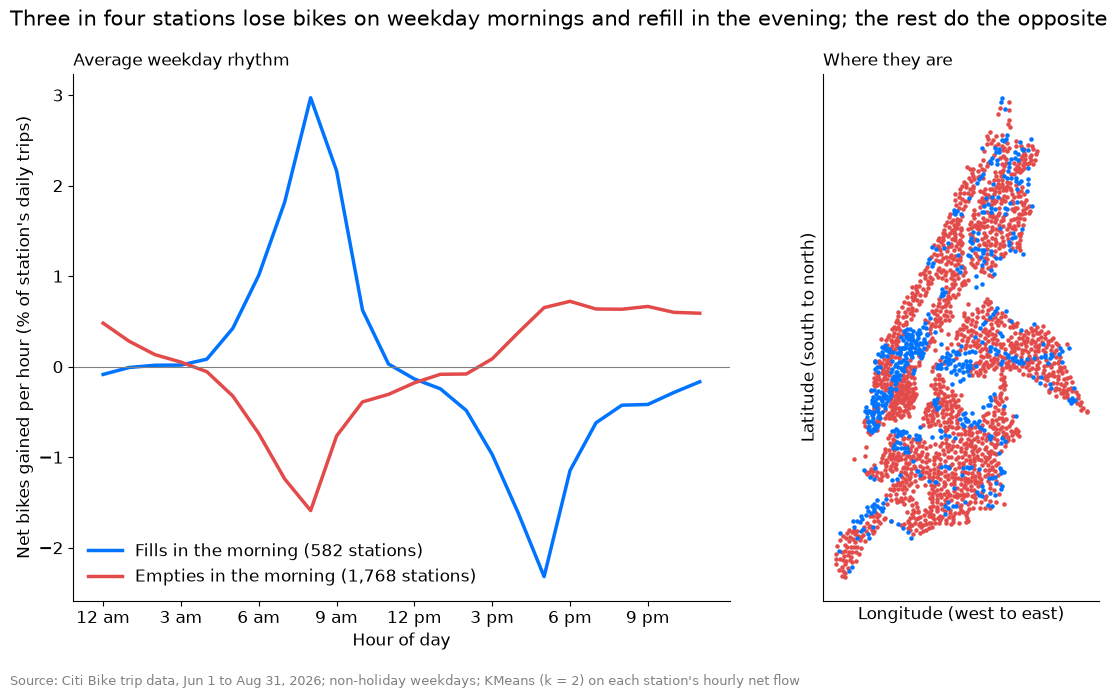

In [15]:
TYPE_COLORS = {"Empties in the morning": RED, "Fills in the morning": BLUE}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 7), gridspec_kw={"width_ratios": [1.5, 1]})

for name, row in centers.iterrows():
    ax1.plot(row.index, row, color=TYPE_COLORS[name], linewidth=2.5, label=f"{name} ({counts[name]:,} stations)")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_xticks(range(0, 24, 3), HOUR_LABELS)
ax1.set(xlabel="Hour of day", ylabel="Net bikes gained per hour (% of station's daily trips)")
ax1.set_title("Average weekday rhythm", loc="left", fontsize=12)
ax1.legend(frameon=False, loc="lower left")

for name, group in station_types.groupby("station_type"):
    ax2.scatter(group["lng"] * np.cos(np.radians(40.73)), group["lat"], s=5, color=TYPE_COLORS[name])
ax2.set_aspect("equal")
ax2.set_xticks([]); ax2.set_yticks([])
ax2.set(xlabel="Longitude (west to east)", ylabel="Latitude (south to north)")
ax2.set_title("Where they are", loc="left", fontsize=12)

fig.suptitle("Three in four stations lose bikes on weekday mornings and refill in the evening; the rest do the opposite", x=0.01, ha="left", fontsize=15)
save_chart(fig, "station_types.png", TRIPS_SOURCE + "; non-holiday weekdays; KMeans (k = 2) on each station's hourly net flow")

1,768 stations (75%) lose bikes in the morning and get them back in the evening, the rhythm of places people live. The other 582 do the opposite, the rhythm of places people work: they gain about 3% of their daily trips in the 8 am hour alone. On the map the fillers are densest in Midtown, but they appear across the city.

## Part 3: Next-day forecast

Predict how many rides start at each station on a given day, using only what is known by the day before: the station's recent rides, the day of the week, holidays, the weather, and the station type from Part 2. Two scikit-learn models are compared against a simple baseline: *the same day last week*.

SQL provides departures per station per day, zero-filled so that a day with no rides is a row with 0 rather than a missing row.

In [16]:
rides = con.sql(query("daily_station_rides")).df()
days_in_span = rides.groupby("station_id")["date"].agg(lambda d: (d.max() - d.min()).days + 1)
assert (rides.groupby("station_id").size() == days_in_span).all()  # one row per station per day
assert not rides.duplicated(["station_id", "date"]).any()
assert (rides["rides"] >= 0).all()
print(f"{len(rides):,} station-days for {rides['station_id'].nunique():,} stations")
rides.head()

209,639 station-days for 2,371 stations


,station_id,date,rides
0,1234.56,2026-06-01,16
1,1234.56,2026-06-02,8
2,1234.56,2026-06-03,13
3,1234.56,2026-06-04,7
4,1234.56,2026-06-05,13


**Features.** Sort by station and date, then build lag features with `groupby(...).shift()`, so each row only sees earlier days of the same station. `avg_last_7` shifts first and then takes the rolling mean, so it covers the 7 days *before* the row's date.

In [17]:
rides = rides.sort_values(["station_id", "date"]).reset_index(drop=True)
by_station = rides.groupby("station_id")["rides"]
rides["rides_yesterday"] = by_station.shift(1)
rides["rides_last_week"] = by_station.shift(7)
rides["avg_last_7"] = by_station.transform(lambda s: s.shift(1).rolling(7).mean())

rides["day_of_week"] = rides["date"].dt.dayofweek  # 0 = Monday
rides["is_holiday"] = rides["date"].isin(holidays_df["date"]).astype(int)
rides = rides.merge(weather, on="date", how="left")
rides = rides.merge(station_types[["station_type"]], left_on="station_id", right_index=True, how="left")
rides["station_type"] = rides["station_type"].fillna("Unclustered")

data = rides.dropna(subset=["rides_yesterday", "rides_last_week", "avg_last_7"]).reset_index(drop=True)
print(f"{len(data):,} rows with a full week of history")
data.head()

193,081 rows with a full week of history


,station_id,date,rides,rides_yesterday,rides_last_week,avg_last_7,day_of_week,is_holiday,temp_max_f,precip_in,station_type
0,1234.56,2026-06-08,17,17.0,16.0,12.571429,0,0,76.1,0.000,Fills in the morning
1,1234.56,2026-06-09,13,17.0,8.0,12.714286,1,0,81.9,0.000,Fills in the morning
2,1234.56,2026-06-10,10,13.0,13.0,13.428571,2,0,84.0,0.110,Fills in the morning
3,1234.56,2026-06-11,17,10.0,7.0,13.000000,3,0,94.2,0.138,Fills in the morning
4,1234.56,2026-06-12,7,17.0,13.0,14.428571,4,0,93.9,0.201,Fills in the morning


Spot-check the busiest station by hand: each lag must equal the value from the right earlier day, and `avg_last_7` must not include the day itself.

In [18]:
check_id = stations["station_id"].iloc[0]  # busiest station
one = rides[rides["station_id"] == check_id].set_index("date")
d, day = one.index[10], pd.Timedelta(days=1)
assert one.loc[d, "rides_yesterday"] == one.loc[d - day, "rides"]
assert one.loc[d, "rides_last_week"] == one.loc[d - 7 * day, "rides"]
assert np.isclose(one.loc[d, "avg_last_7"], one.loc[d - 7 * day : d - day, "rides"].mean())
one.loc[d - 7 * day : d, ["rides", "rides_yesterday", "rides_last_week", "avg_last_7"]]

,rides,rides_yesterday,rides_last_week,avg_last_7
date,,,,
2026-06-04,640,674.0,NaN,NaN
2026-06-05,626,640.0,NaN,NaN
2026-06-06,484,626.0,NaN,NaN
2026-06-07,496,484.0,NaN,NaN
2026-06-08,661,496.0,624.0,601.714286
2026-06-09,684,661.0,668.0,607.000000
2026-06-10,651,684.0,674.0,609.285714
2026-06-11,621,651.0,640.0,606.000000


**Split.** The last 14 days are the test set, used once at the very end. Everything earlier is training.

In [19]:
all_dates = np.sort(data["date"].unique())
test_start = all_dates[-14]
train = data[data["date"] < test_start]
test = data[data["date"] >= test_start]
assert train["date"].max() < test["date"].min()
print(f"Train: {train['date'].min():%b %-d} to {train['date'].max():%b %-d} ({train['date'].nunique()} days, {len(train):,} rows)")
print(f"Test:  {test['date'].min():%b %-d} to {test['date'].max():%b %-d} ({test['date'].nunique()} days, {len(test):,} rows)")

Train: Jun 8 to Aug 17 (71 days, 160,940 rows)
Test:  Aug 18 to Aug 31 (14 days, 32,141 rows)


**Metrics.** MAE (average miss, in rides) and RMSE (punishes big misses more), written out in NumPy and checked against scikit-learn.

In [20]:
def mae(y, pred):
    return np.mean(np.abs(np.asarray(y) - np.asarray(pred)))


def rmse(y, pred):
    return np.sqrt(np.mean((np.asarray(y) - np.asarray(pred)) ** 2))


assert np.isclose(mae(train["rides"], train["rides_last_week"]), mean_absolute_error(train["rides"], train["rides_last_week"]))
assert np.isclose(rmse(train["rides"], train["rides_last_week"]), root_mean_squared_error(train["rides"], train["rides_last_week"]))

**Models.** Ridge is a linear model, so categories are one-hot encoded and numbers are scaled. Gradient boosting uses trees, which need no scaling, so categories are simply integer-coded. Both are pipelines, so they take the same input table.

In [21]:
CATEGORICAL = ["day_of_week", "station_type"]
NUMERIC = ["rides_yesterday", "rides_last_week", "avg_last_7", "is_holiday", "temp_max_f", "precip_in"]
FEATURES = CATEGORICAL + NUMERIC
BASELINE = "Baseline (same day last week)"

ridge = Pipeline([
    ("prep", ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
        ("numbers", StandardScaler(), NUMERIC),
    ])),
    ("model", Ridge()),
])
boosting = Pipeline([
    ("prep", ColumnTransformer(
        [("categories", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL)],
        remainder="passthrough",
    )),
    ("model", HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=42)),
])
models = {"Ridge": ridge, "Gradient boosting": boosting}

**Cross-validation on the training period only.** `TimeSeriesSplit` runs on the sorted unique training dates, and rows are then picked by date. Each fold trains on earlier days and validates on the days right after them, and no day is split across folds.

In [22]:
train_dates = np.sort(train["date"].unique())
fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=4).split(train_dates), start=1):
    fit = train[train["date"].isin(train_dates[fit_idx])]
    val = train[train["date"].isin(train_dates[val_idx])]
    row = {"fold": fold, BASELINE: mae(val["rides"], val["rides_last_week"])}
    for name, model in models.items():
        model.fit(fit[FEATURES], fit["rides"])
        row[name] = mae(val["rides"], model.predict(val[FEATURES]))
    fold_rows.append(row)

cv = pd.DataFrame(fold_rows).set_index("fold")
cv_summary = cv.agg(["mean", "std"]).T.round(2)
cv_summary.columns = ["mean MAE", "std MAE"]
best_name = cv_summary.drop(BASELINE)["mean MAE"].idxmin()
print("Chosen model:", best_name)
cv_summary

Chosen model: Gradient boosting


,mean MAE,std MAE
Baseline (same day last week),19.70,4.31
Ridge,18.06,3.35
Gradient boosting,15.68,1.62


**Test once.** Refit the chosen model on all training days and score it on the 14 held-out days.

In [23]:
final_model = models[best_name].fit(train[FEATURES], train["rides"])
test = test.assign(prediction=final_model.predict(test[FEATURES]))

test_results = pd.DataFrame({
    "MAE": [mae(test["rides"], test["rides_last_week"]), mae(test["rides"], test["prediction"])],
    "RMSE": [rmse(test["rides"], test["rides_last_week"]), rmse(test["rides"], test["prediction"])],
}, index=[BASELINE, best_name])
assert np.isclose(test_results.loc[best_name, "MAE"], mean_absolute_error(test["rides"], test["prediction"]))
assert np.isclose(test_results.loc[best_name, "RMSE"], root_mean_squared_error(test["rides"], test["prediction"]))
test_results.loc["Improvement (%)"] = (1 - test_results.loc[best_name] / test_results.loc[BASELINE]) * 100
test_results.round(2)

,MAE,RMSE
Baseline (same day last week),14.53,30.72
Gradient boosting,13.44,26.24
Improvement (%),7.51,14.57


Cross-validation picked gradient boosting clearly: mean MAE 15.68 (std 1.62) against 18.06 for Ridge and 19.70 for the baseline. On the 14 held-out test days it misses by 13.44 rides per station-day on average, against 14.53 for the baseline: 7.5% better on MAE and 14.6% better on RMSE, so it avoids more of the big misses. The gain is modest, which is normal: the same day last week is already a strong forecast.

Where does the model help? Compare the errors by station size (average daily rides over the previous 7 days) and station by station.

In [24]:
errors = pd.DataFrame({
    "baseline MAE": (test["rides"] - test["rides_last_week"]).abs(),
    "model MAE": (test["rides"] - test["prediction"]).abs(),
})
per_station = errors.groupby(test["station_id"]).mean()
print(f"The model beats the baseline at {(per_station['model MAE'] < per_station['baseline MAE']).mean():.0%} of stations")

size = pd.cut(test["avg_last_7"], [0, 20, 100, 200, np.inf], right=False, labels=["under 20", "20-100", "100-200", "200+"])
by_size = errors.groupby(size, observed=True).mean()
by_size["improvement (%)"] = (1 - by_size["model MAE"] / by_size["baseline MAE"]) * 100
by_size.round(1)

The model beats the baseline at 74% of stations


,baseline MAE,model MAE,improvement (%)
avg_last_7,,,
under 20,4.1,3.3,18.7
20-100,10.8,9.3,14.0
100-200,27.4,25.2,8.0
200+,45.9,47.1,-2.4


W 21 St & 6 Ave: baseline MAE 37.7, Gradient boosting MAE 71.6


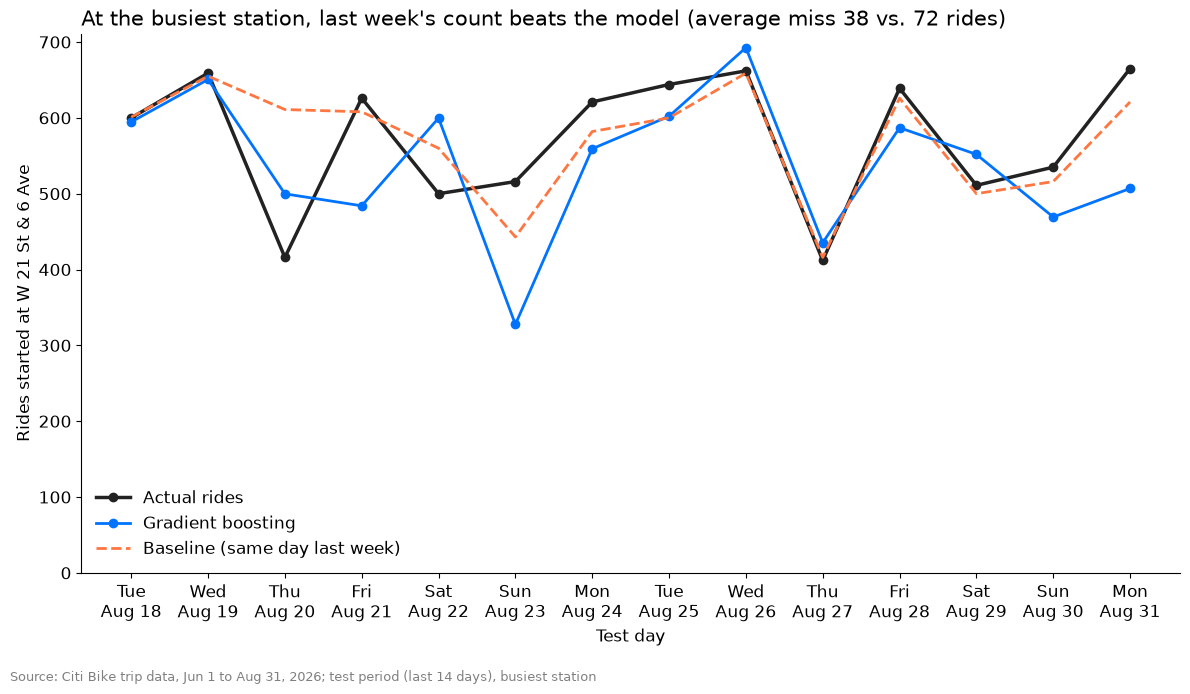

In [25]:
busiest = test.groupby("station_id")["rides"].sum().idxmax()
one_station = test[test["station_id"] == busiest]
station_name = stations.set_index("station_id").loc[busiest, "name"]
print(f"{station_name}: baseline MAE {mae(one_station['rides'], one_station['rides_last_week']):.1f}, "
      f"{best_name} MAE {mae(one_station['rides'], one_station['prediction']):.1f}")

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(one_station["date"], one_station["rides"], color="#222222", linewidth=2.5, marker="o", label="Actual rides")
ax.plot(one_station["date"], one_station["prediction"], color=BLUE, linewidth=2, marker="o", label=best_name)
ax.plot(one_station["date"], one_station["rides_last_week"], color=ORANGE, linewidth=2, linestyle="--", label=BASELINE)
ax.set_xticks(one_station["date"], one_station["date"].dt.strftime("%a\n%b %-d"))
ax.set_ylim(bottom=0)
ax.set(xlabel="Test day", ylabel=f"Rides started at {station_name}")
ax.set_title("At the busiest station, last week's count beats the model (average miss 38 vs. 72 rides)", loc="left", fontsize=15)
ax.legend(frameon=False, loc="lower left")
save_chart(fig, "forecast_vs_actual.png", TRIPS_SOURCE + "; test period (last 14 days), busiest station")

The model does better at 74% of stations, most of all at small and mid-sized ones (14 to 19% lower MAE below 100 rides a day). At the busiest stations (200+ rides a day) it is slightly worse than the baseline (2.4% higher MAE), and the single busiest station, shown here, is the clearest case. That station repeats almost the same week every week, so last week's count is hard to beat, while the model sometimes over-reacts: on Sunday, Aug 23 it predicted far fewer rides than happened.

**Which features does the model lean on?** Permutation importance shuffles one feature at a time in the test set and measures how much the MAE gets worse. This explains the chosen model after the fact; it was not used to choose it.

In [26]:
result = permutation_importance(final_model, test[FEATURES], test["rides"], scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=42)
importance = pd.Series(result.importances_mean, index=FEATURES).sort_values()
importance.sort_values(ascending=False).round(2)  # rise in MAE (rides) when the feature is shuffled

avg_last_7         27.94
rides_yesterday    21.69
rides_last_week    11.50
precip_in           3.17
station_type        0.13
is_holiday          0.00
day_of_week        -0.03
temp_max_f         -0.44
dtype: float64

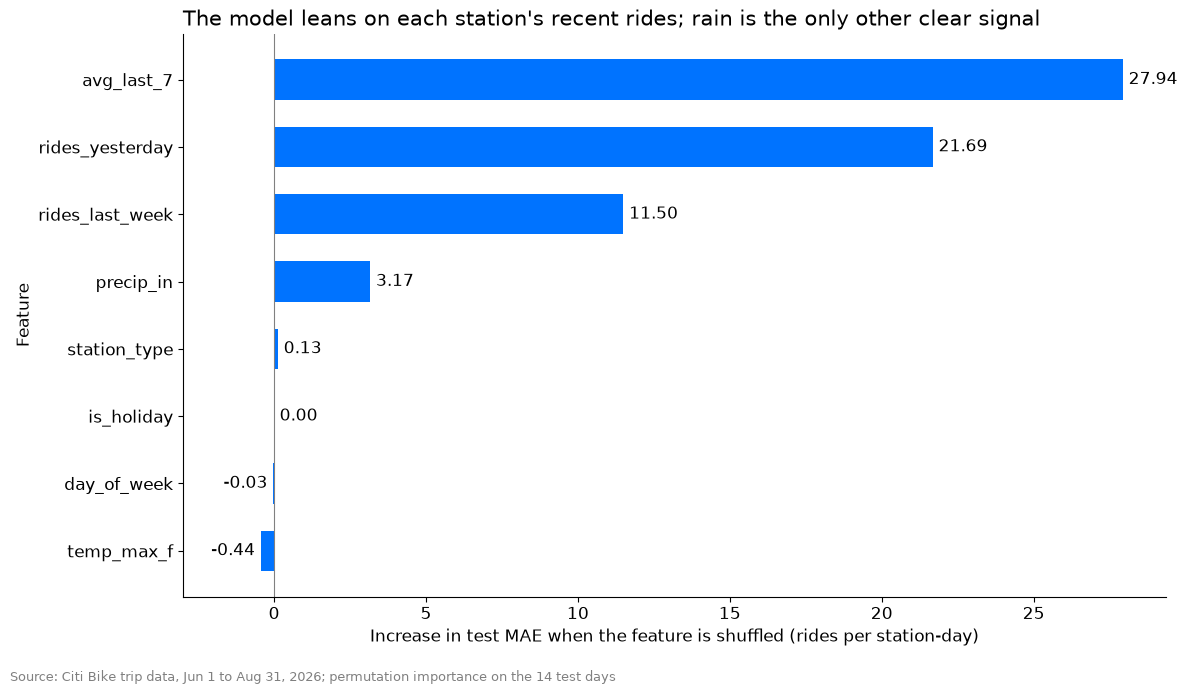

In [27]:
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(importance.index, importance, color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlim(left=-3)  # room for the labels of negative bars
ax.set(xlabel="Increase in test MAE when the feature is shuffled (rides per station-day)", ylabel="Feature")
ax.set_title("The model leans on each station's recent rides; rain is the only other clear signal", loc="left", fontsize=15)
save_chart(fig, "feature_importance.png", TRIPS_SOURCE + "; permutation importance on the 14 test days")

Recent history dominates: shuffling the 7-day average raises the test MAE by 27.9 rides, yesterday's rides by 21.7, and last week's by 11.5. Rain adds 3.2. The rest are near zero. The test period has no holidays, so `is_holiday` cannot matter there. Shuffling temperature or day of week slightly *lowers* the MAE, so the model gets nothing useful from them on these days, probably because the lag features already carry the weekly pattern.

**Caveat:** the test uses the *actual* weather of each test day. A real next-day forecast would use a weather forecast, which is less accurate, so these results are slightly optimistic.